# Tahap 7 — Evaluasi, Uji DM, dan Gerbang Penerimaan Utama

Notebook ini membangun ulang evaluasi headline dari kontrak Tahap 7 dengan
logika yang dipindahkan langsung dari modul evaluasi otoritatif. Fokusnya
adalah membuktikan D7, D9, D10, dan D11 pada artefak prediksi yang sudah
dibundel dari Tahap 6.

In [1]:
from __future__ import annotations
from pathlib import Path
import json
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
SEED = int(CFG["seed"])
np.random.seed(SEED)

def rp(*parts: str) -> Path:
    """Resolve a repo-relative path (parts are path fragments under the repo root)."""
    return ROOT.joinpath(*parts)

BRAND_COLORS = {"OPPO": "#0072B2", "Realme": "#D55E00", "Samsung": "#009E73",
                "Vivo": "#CC79A7", "Xiaomi": "#E69F00"}
ALGO_COLORS = {"SARIMAX": "#0072B2", "RF": "#D55E00", "LSTM": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.5),
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12})

Sasaran D7 dinyatakan eksplisit: model pemenang harus memiliki `MASE < 1`
dan juga unggul signifikan terhadap baseline naif menurut uji
Diebold–Mariano. Pemeriksaan ini hanya sah bila semua galat berasal dari
rezim evaluasi yang sepadan (D9), sehingga notebook ini memverifikasi
keselarasan origin dan `y_true` lebih dulu.

D10 menambahkan dua konteks penting. Pertama, MASE dipakai karena tetap stabil
pada banyak minggu nol, berbeda dari MAPE. Kedua, sMAPE sekitar 84% pada data
hitung diskrit ber-volume rendah masih bisa dekat dengan lantai teoretis sekitar
67%, jadi angka besar itu bukan otomatis tanda model buruk. D11 kemudian
menutup siklus evaluasi: kandidat baru hanya diadopsi jika signifikan lebih baik
daripada pemenang lama, dan hasil akhirnya memang 0 dari 10 kandidat.

In [2]:
import logging
from IPython.display import display
from scipy import stats

logger = logging.getLogger("notebook.07_evaluation")

ALGOS = ["sarimax", "rf", "lstm"]
VARIANTS = ["baseline", "gt"]
ALGO_LABEL = {"sarimax": "SARIMAX", "rf": "RF", "lstm": "LSTM"}
NAIVE_METHODS = ["naive", "snaive"]
PREDICTION_COLUMNS = ["store", "brand", "week_start", "y_true", "y_pred"]
MAIN_PREDICTIONS = tuple(f"predictions_{algo}_{variant}.parquet" for algo in ALGOS for variant in VARIANTS)
NAIVE_PREDICTIONS = tuple(f"predictions_{method}.parquet" for method in NAIVE_METHODS)
CANDIDATE_SPECS = [
    ("RF-Poisson(baseline)", "predictions_rf_poisson_baseline.parquet"),
    ("RF-Poisson(gt)", "predictions_rf_poisson_gt.parquet"),
    ("HGB-Poisson(baseline)", "predictions_hgb_poisson_baseline.parquet"),
    ("HGB-Poisson(gt)", "predictions_hgb_poisson_gt.parquet"),
    ("Croston", "predictions_croston.parquet"),
    ("TSB", "predictions_tsb.parquet"),
    ("Ensemble-mean(baseline)", "predictions_ensemble_mean_baseline.parquet"),
    ("Ensemble-mean(gt)", "predictions_ensemble_mean_gt.parquet"),
    ("Ensemble-invMAE(baseline)", "predictions_ensemble_invmae_baseline.parquet"),
    ("Ensemble-invMAE(gt)", "predictions_ensemble_invmae_gt.parquet"),
]
EXPECTED_PREDICTION_FILES = MAIN_PREDICTIONS + NAIVE_PREDICTIONS + tuple(fname for _, fname in CANDIDATE_SPECS)
RESULTS_DIR = rp(*Path(CFG["paths"]["results"]).parts)
FIGURES_DIR = rp(*Path(CFG["paths"]["figures"]).parts)
FIGURE_AUDIT: list[dict] = []


def cfg_path(cfg: dict, key: str) -> Path:
    """Resolve a configured relative path under the notebook repo root."""
    return rp(*Path(cfg["paths"][key]).parts)

## Memuat dan memverifikasi input prediksi

Tahap 7 harus membaca tepat 18 tabel `predictions_*.parquet`: enam model utama,
dua baseline naif, dan sepuluh kandidat D11. Setiap tabel wajib memakai skema
yang sama agar perbandingan DM benar-benar membandingkan galat pada origin yang
identik.

In [3]:
prediction_file_list = sorted(path.name for path in RESULTS_DIR.glob("predictions_*.parquet"))
assert prediction_file_list == sorted(EXPECTED_PREDICTION_FILES), prediction_file_list

prediction_shapes = {}
for filename in prediction_file_list:
    frame = pd.read_parquet(RESULTS_DIR / filename)
    assert frame.columns.tolist() == PREDICTION_COLUMNS, (filename, frame.columns.tolist())
    assert frame.shape == (740, 5), (filename, frame.shape)
    prediction_shapes[filename] = frame.shape

print(f"Memuat {len(prediction_file_list)} file prediksi dengan skema yang selaras untuk evaluasi Tahap 7.")

Memuat 18 file prediksi dengan skema yang selaras untuk evaluasi Tahap 7.


## Metrik yang dihitung

Notebook ini menghitung MAE, RMSE, MAPE, sMAPE, dan MASE.

- MAE dan RMSE selalu terdefinisi, sehingga aman untuk data dengan banyak nol.
- MAPE hanya dihitung pada minggu dengan aktual tidak nol.
- sMAPE memakai konvensi aman `0/0 -> 0`.
- MASE membandingkan MAE model terhadap baseline naif per deret. Karena itu,
  `MASE < 1` berarti model lebih baik daripada tebakan sederhana “minggu ini
  sama dengan minggu lalu”, yang persis menjadi syarat D7/D10.

In [4]:
def mae(y_true, y_pred) -> float:
    a, p = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.mean(np.abs(a - p)))


def rmse(y_true, y_pred) -> float:
    a, p = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.sqrt(np.mean((a - p) ** 2)))


def mape(y_true, y_pred) -> float:
    """MAPE (%) dihitung HANYA pada aktual != 0. NaN bila tak ada minggu non-nol."""
    a, p = np.asarray(y_true, float), np.asarray(y_pred, float)
    mask = a != 0
    if not mask.any():
        return float("nan")
    return float(np.mean(np.abs((a[mask] - p[mask]) / a[mask])) * 100.0)


def smape(y_true, y_pred) -> float:
    """sMAPE (%) aman pada nol: konvensi 0/0 -> 0. Rentang [0,200]."""
    a, p = np.asarray(y_true, float), np.asarray(y_pred, float)
    denom = np.abs(a) + np.abs(p)
    num = 2.0 * np.abs(p - a)
    term = np.divide(num, denom, out=np.zeros_like(num), where=denom != 0)
    return float(np.mean(term) * 100.0)


def mase(y_true, y_pred, naive_mae: float | None) -> float:
    """MASE = MAE model / MAE naive (denominator per deret, D10). NaN bila denom tak valid."""
    if naive_mae is None or not np.isfinite(naive_mae) or naive_mae <= 0:
        return float("nan")
    return float(mae(y_true, y_pred) / naive_mae)


def _mean(values) -> float:
    v = np.asarray(values, float)
    return float(np.nanmean(v)) if np.isfinite(v).any() else float("nan")


def _wmean(values, weights) -> float:
    """Rata-rata berbobot; abaikan NaN & bobot non-positif."""
    v, w = np.asarray(values, float), np.asarray(weights, float)
    m = ~np.isnan(v) & (w > 0)
    if not m.any():
        return float("nan")
    return float(np.sum(v[m] * w[m]) / np.sum(w[m]))


def series_metrics(y_true, y_pred, naive_mae: float | None = None) -> dict:
    a = np.asarray(y_true, float)
    return {
        "MAE": mae(a, y_pred), "RMSE": rmse(a, y_pred),
        "MAPE": mape(a, y_pred), "sMAPE": smape(a, y_pred),
        "MASE": mase(a, y_pred, naive_mae),
        "n": int(a.size), "n_nonzero": int((a != 0).sum()),
        "volume": float(a.sum()),
    }


def load_predictions(results_dir: str | Path) -> dict[tuple[str, str], pd.DataFrame]:
    """Muat 6 file prediksi model utama -> {(algo, variant): df}."""
    results_dir = Path(results_dir)
    out: dict[tuple[str, str], pd.DataFrame] = {}
    for algo in ALGOS:
        for variant in VARIANTS:
            path = results_dir / f"predictions_{algo}_{variant}.parquet"
            if path.exists():
                out[(algo, variant)] = pd.read_parquet(path)
            else:
                logger.warning("Prediksi hilang: %s", path)
    return out


def load_naive_predictions(results_dir: str | Path) -> dict[str, pd.DataFrame]:
    """Muat baseline naif (D10) -> {method: df}. Kosong bila belum ada."""
    results_dir = Path(results_dir)
    out: dict[str, pd.DataFrame] = {}
    for method in NAIVE_METHODS:
        path = results_dir / f"predictions_{method}.parquet"
        if path.exists():
            out[method] = pd.read_parquet(path)
    return out


def load_candidate_predictions(results_dir: str | Path) -> dict[str, pd.DataFrame]:
    """Muat kandidat perbaikan akurasi Tahap 6e (D11) -> {label: df}. Kosong bila belum ada."""
    results_dir = Path(results_dir)
    out: dict[str, pd.DataFrame] = {}
    for label, fname in CANDIDATE_SPECS:
        path = results_dir / fname
        if path.exists():
            out[label] = pd.read_parquet(path)
    return out


def naive_mae_lookup(naive_df: pd.DataFrame) -> dict[tuple[str, str], float]:
    """MAE naif per deret -> denominator MASE (D10)."""
    out: dict[tuple[str, str], float] = {}
    for (store, brand), g in naive_df.groupby(["store", "brand"]):
        out[(store, brand)] = mae(g["y_true"].to_numpy(), g["y_pred"].to_numpy())
    return out


def per_series_metrics(
    preds: dict[tuple[str, str], pd.DataFrame],
    naive_mae: dict[tuple[str, str], float] | None = None,
) -> pd.DataFrame:
    """Tabel panjang: satu baris per (algo, varian, store, brand). MASE bila naive_mae ada."""
    rows = []
    for (algo, variant), df in preds.items():
        for (store, brand), g in df.groupby(["store", "brand"]):
            g = g.sort_values("week_start")
            nm = None if naive_mae is None else naive_mae.get((store, brand))
            m = series_metrics(g["y_true"].to_numpy(), g["y_pred"].to_numpy(), naive_mae=nm)
            rows.append({"algo": algo, "variant": variant, "store": store, "brand": brand, **m})
    return pd.DataFrame(rows)


def summary_from_per_series(per_series: pd.DataFrame) -> pd.DataFrame:
    """Ringkasan (algo, varian): metrik mean & weighted-by-volume antar-deret."""
    rows = []
    for (algo, variant), g in per_series.groupby(["algo", "variant"]):
        w = g["volume"].to_numpy()
        rows.append({
            "algo": algo, "variant": variant, "n_series": int(len(g)),
            "MAE_mean": _mean(g["MAE"]), "RMSE_mean": _mean(g["RMSE"]),
            "MAPE_mean": _mean(g["MAPE"]), "sMAPE_mean": _mean(g["sMAPE"]),
            "MASE_mean": _mean(g["MASE"]) if "MASE" in g else float("nan"),
            "MAE_wmean": _wmean(g["MAE"], w), "RMSE_wmean": _wmean(g["RMSE"], w),
            "MAPE_wmean": _wmean(g["MAPE"], w), "sMAPE_wmean": _wmean(g["sMAPE"], w),
            "MASE_wmean": _wmean(g["MASE"], w) if "MASE" in g else float("nan"),
        })
    summary = pd.DataFrame(rows)
    summary["algo"] = pd.Categorical(summary["algo"], ALGOS, ordered=True)
    summary["variant"] = pd.Categorical(summary["variant"], VARIANTS, ordered=True)
    summary = summary.sort_values(["algo", "variant"]).reset_index(drop=True)
    summary["algo"] = summary["algo"].astype(str)
    summary["variant"] = summary["variant"].astype(str)
    summary["is_best"] = summary["MAE_mean"] == summary["MAE_mean"].min()
    return summary


def best_variant_by_mae(summary: pd.DataFrame) -> dict[str, str]:
    """Varian terbaik per algoritma (MAE_mean terendah) — untuk perbandingan antar-algo."""
    best = {}
    for algo in ALGOS:
        sub = summary[summary["algo"] == algo]
        if len(sub):
            best[algo] = str(sub.loc[sub["MAE_mean"].idxmin(), "variant"])
    return best


def baseline_summary(
    baseline_preds: dict[str, pd.DataFrame],
    naive_mae: dict[tuple[str, str], float],
) -> pd.DataFrame:
    """Baris ringkasan untuk baseline naif (D10) — format kolom sama dgn summary utama."""
    rows = []
    for name, df in baseline_preds.items():
        per = []
        for (store, brand), g in df.groupby(["store", "brand"]):
            g = g.sort_values("week_start")
            per.append(series_metrics(g["y_true"].to_numpy(), g["y_pred"].to_numpy(),
                                      naive_mae=naive_mae.get((store, brand))))
        pdf = pd.DataFrame(per)
        w = pdf["volume"].to_numpy()
        rows.append({
            "algo": name, "variant": "-", "n_series": int(len(pdf)),
            "MAE_mean": _mean(pdf["MAE"]), "RMSE_mean": _mean(pdf["RMSE"]),
            "MAPE_mean": _mean(pdf["MAPE"]), "sMAPE_mean": _mean(pdf["sMAPE"]),
            "MASE_mean": _mean(pdf["MASE"]),
            "MAE_wmean": _wmean(pdf["MAE"], w), "RMSE_wmean": _wmean(pdf["RMSE"], w),
            "MAPE_wmean": _wmean(pdf["MAPE"], w), "sMAPE_wmean": _wmean(pdf["sMAPE"], w),
            "MASE_wmean": _wmean(pdf["MASE"], w), "is_best": False,
        })
    return pd.DataFrame(rows)


def smape_theoretical_floor(
    preds: dict[tuple[str, str], pd.DataFrame],
    best_key: tuple[str, str],
    seed: int = 42,
    n_sim: int = 50000,
) -> pd.DataFrame:
    """Lantai teoretis sMAPE per deret (D10, konteks Bab IV — BUKAN kriteria lulus)."""
    rng = np.random.default_rng(seed)
    best_df = preds[best_key]
    rows = []
    for (store, brand), g in best_df.groupby(["store", "brand"]):
        g = g.sort_values("week_start")
        a = g["y_true"].to_numpy()
        lam = float(a.mean())
        sim = rng.poisson(lam, size=n_sim).astype(float) if lam > 0 else np.zeros(n_sim)
        floor = smape(sim, np.full(n_sim, lam))
        rows.append({
            "store": store,
            "brand": brand,
            "lambda_test": round(lam, 4),
            "smape_floor_oracle": round(floor, 2),
            "smape_actual_best": round(smape(a, g["y_pred"].to_numpy()), 2),
        })
    df = pd.DataFrame(rows)
    df["gap_vs_floor"] = (df["smape_actual_best"] - df["smape_floor_oracle"]).round(2)
    return df

## Empat kelompok uji Diebold–Mariano

Kelompok `antar_algoritma` membandingkan algoritma pada varian terbaiknya
masing-masing. Kelompok `ablation_gt` menjawab apakah Google Trends benar-benar
membantu tiap algoritma. Kelompok `vs_naive` menguji syarat D7/D10 langsung
terhadap `naive` dan `snaive`. Kelompok `kandidat_akurasi` dipakai untuk D11:
kandidat baru boleh menang hanya jika signifikan lebih baik dari pemenang lama.

In [5]:
_KEYS = ["store", "brand", "week_start"]


def _loss(err: np.ndarray, kind: str) -> np.ndarray:
    if kind == "squared":
        return err ** 2
    if kind == "absolute":
        return np.abs(err)
    raise ValueError(f"loss tak dikenal: {kind}")


def diebold_mariano(y_true, pred1, pred2, h: int = 1, loss: str = "squared") -> dict:
    """Uji DM dua sisi dgn koreksi HLN. `better`=1 jika model1 loss lebih rendah."""
    a = np.asarray(y_true, float)
    e1 = a - np.asarray(pred1, float)
    e2 = a - np.asarray(pred2, float)
    d = _loss(e1, loss) - _loss(e2, loss)
    T = d.size
    dbar = float(d.mean())

    d0 = d - dbar
    gamma0 = float(np.mean(d0 * d0))
    lrv = gamma0
    for k in range(1, h):
        gamma_k = float(np.mean(d0[k:] * d0[:-k]))
        lrv += 2.0 * gamma_k
    var_dbar = lrv / T

    better = 1 if dbar < 0 else (2 if dbar > 0 else 0)
    if var_dbar <= 0 or T < 2:
        if dbar == 0 or T < 2:
            return {"dm_stat": 0.0, "p_value": 1.0, "mean_diff": dbar, "n": int(T), "better": 0}
        return {"dm_stat": float(np.sign(dbar) * np.inf), "p_value": 0.0,
                "mean_diff": dbar, "n": int(T), "better": better}

    dm = dbar / np.sqrt(var_dbar)
    corr = (T + 1 - 2 * h + h * (h - 1) / T) / T
    dm_star = dm * np.sqrt(max(corr, 0.0))
    p_value = float(2.0 * stats.t.cdf(-abs(dm_star), df=T - 1))
    return {"dm_stat": float(dm_star), "p_value": p_value, "mean_diff": dbar, "n": int(T), "better": better}


def align_frames(df1: pd.DataFrame, df2: pd.DataFrame) -> pd.DataFrame:
    """Gabung dua frame prediksi pada origin sepadan; verifikasi y_true identik (D9)."""
    m = df1[_KEYS + ["y_true", "y_pred"]].merge(
        df2[_KEYS + ["y_true", "y_pred"]], on=_KEYS, suffixes=("_1", "_2")
    )
    if len(m) != len(df1) or len(m) != len(df2):
        raise ValueError(
            "Origin forecast tak sepadan antar-model (pelanggaran D9): "
            f"{len(df1)} & {len(df2)} baris -> {len(m)} cocok."
        )
    if not np.allclose(m["y_true_1"].to_numpy(), m["y_true_2"].to_numpy()):
        raise ValueError("y_true berbeda pada origin yang sama (pelanggaran D9).")
    return m.sort_values(_KEYS).reset_index(drop=True)


def dm_from_frames(df1: pd.DataFrame, df2: pd.DataFrame, h: int = 1, loss: str = "squared") -> dict:
    """Uji DM pada loss ter-pool di seluruh deret×minggu, origin tervalidasi (D9)."""
    m = align_frames(df1, df2)
    return diebold_mariano(m["y_true_1"], m["y_pred_1"], m["y_pred_2"], h=h, loss=loss)


def run_comparisons(
    preds: dict[tuple[str, str], pd.DataFrame],
    best_variant: dict[str, str],
    loss: str = "squared",
    naive_preds: dict[str, pd.DataFrame] | None = None,
) -> pd.DataFrame:
    """dm_tests.csv: antar-algoritma + ablation GT + (opsional) vs-naif (D10)."""
    rows = []

    for a1, a2 in [("sarimax", "rf"), ("sarimax", "lstm"), ("rf", "lstm")]:
        v1, v2 = best_variant.get(a1), best_variant.get(a2)
        if (a1, v1) not in preds or (a2, v2) not in preds:
            continue
        r = dm_from_frames(preds[(a1, v1)], preds[(a2, v2)], loss=loss)
        winner = {1: f"{ALGO_LABEL[a1]}({v1})", 2: f"{ALGO_LABEL[a2]}({v2})", 0: "seri"}[r["better"]]
        rows.append({
            "group": "antar_algoritma",
            "model1": f"{ALGO_LABEL[a1]}({v1})",
            "model2": f"{ALGO_LABEL[a2]}({v2})",
            "dm_stat": r["dm_stat"],
            "p_value": r["p_value"],
            "n": r["n"],
            "significant": bool(r["p_value"] < 0.05),
            "better": winner if r["p_value"] < 0.05 else "tak signifikan",
        })

    for algo in ALGOS:
        if (algo, "baseline") not in preds or (algo, "gt") not in preds:
            continue
        r = dm_from_frames(preds[(algo, "baseline")], preds[(algo, "gt")], loss=loss)
        winner = {1: f"{ALGO_LABEL[algo]}(baseline)", 2: f"{ALGO_LABEL[algo]}(gt)", 0: "seri"}[r["better"]]
        rows.append({
            "group": "ablation_gt",
            "model1": f"{ALGO_LABEL[algo]}(baseline)",
            "model2": f"{ALGO_LABEL[algo]}(gt)",
            "dm_stat": r["dm_stat"],
            "p_value": r["p_value"],
            "n": r["n"],
            "significant": bool(r["p_value"] < 0.05),
            "better": winner if r["p_value"] < 0.05 else "tak signifikan",
        })

    if naive_preds:
        for algo in ALGOS:
            v = best_variant.get(algo)
            if (algo, v) not in preds:
                continue
            model_label = f"{ALGO_LABEL[algo]}({v})"
            for method, ndf in naive_preds.items():
                r = dm_from_frames(preds[(algo, v)], ndf, loss=loss)
                winner = {1: model_label, 2: method, 0: "seri"}[r["better"]]
                rows.append({
                    "group": "vs_naive",
                    "model1": model_label,
                    "model2": method,
                    "dm_stat": r["dm_stat"],
                    "p_value": r["p_value"],
                    "n": r["n"],
                    "significant": bool(r["p_value"] < 0.05),
                    "better": winner if r["p_value"] < 0.05 else "tak signifikan",
                })

    return pd.DataFrame(rows)


def _agg_mae_mase(df: pd.DataFrame, naive_mae: dict[tuple[str, str], float] | None) -> tuple[float, float]:
    """Rata-rata antar-deret MAE & MASE untuk satu set prediksi (kolom kompatibel Tahap 7)."""
    maes, mases = [], []
    for (store, brand), g in df.groupby(["store", "brand"]):
        g = g.sort_values("week_start")
        a, p = g["y_true"].to_numpy(), g["y_pred"].to_numpy()
        maes.append(mae(a, p))
        nm = None if naive_mae is None else naive_mae.get((store, brand))
        mases.append(mase(a, p, nm))
    mase_arr = np.asarray(mases, float)
    mase_mean = float(np.nanmean(mase_arr)) if np.isfinite(mase_arr).any() else float("nan")
    return float(np.nanmean(maes)), mase_mean


def compare_candidates(
    preds: dict[tuple[str, str], pd.DataFrame],
    best_key: tuple[str, str],
    candidate_preds: dict[str, pd.DataFrame],
    naive_mae: dict[tuple[str, str], float] | None = None,
    loss: str = "squared",
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Kelompok 4 (D11): pemenang lama vs tiap kandidat 6e -> (dm_rows, verdict)."""
    old = preds[best_key]
    old_label = f"{ALGO_LABEL[best_key[0]]}({best_key[1]})"
    old_mae, old_mase = _agg_mae_mase(old, naive_mae)

    dm_rows = []
    verdict_rows = [{
        "candidate": f"{old_label} [pemenang lama]",
        "MAE_mean": round(old_mae, 4),
        "MASE_mean": round(old_mase, 4),
        "dm_stat": np.nan,
        "p_value_vs_old_winner": np.nan,
        "signif_better_than_old": False,
        "decision": "REFERENSI (pemenang Tahap 7)",
    }]

    for label, cand in candidate_preds.items():
        r = dm_from_frames(old, cand, loss=loss)
        cand_mae, cand_mase = _agg_mae_mase(cand, naive_mae)
        sig = r["p_value"] < 0.05
        adopt = bool(sig and r["better"] == 2)
        if adopt:
            decision = "ADOPSI (signifikan lebih baik)"
        elif sig and r["better"] == 1:
            decision = "tolak (signifikan LEBIH BURUK dari pemenang lama)"
        else:
            decision = "tolak (tak berbeda signifikan)"
        dm_rows.append({
            "group": "kandidat_akurasi",
            "model1": old_label,
            "model2": label,
            "dm_stat": r["dm_stat"],
            "p_value": r["p_value"],
            "n": r["n"],
            "significant": bool(sig),
            "better": (label if adopt else old_label if (sig and r["better"] == 1) else "tak signifikan"),
        })
        verdict_rows.append({
            "candidate": label,
            "MAE_mean": round(cand_mae, 4),
            "MASE_mean": round(cand_mase, 4),
            "dm_stat": round(r["dm_stat"], 4),
            "p_value_vs_old_winner": round(r["p_value"], 4),
            "signif_better_than_old": adopt,
            "decision": decision,
        })
    return pd.DataFrame(dm_rows), pd.DataFrame(verdict_rows)


def build_gt_ablation(preds: dict[tuple[str, str], pd.DataFrame], loss: str = "squared") -> pd.DataFrame:
    """gt_ablation_comparison.csv: per (algo, deret) baseline vs gt + baris ringkasan."""
    rows, summary_rows = [], []
    for algo in ALGOS:
        if (algo, "baseline") not in preds or (algo, "gt") not in preds:
            continue
        b = preds[(algo, "baseline")]
        g = preds[(algo, "gt")]
        m = align_frames(b, g)
        n_better = n_worse = n_ns = 0
        for (store, brand), grp in m.groupby(["store", "brand"]):
            grp = grp.sort_values("week_start")
            a = grp["y_true_1"].to_numpy()
            pb, pg = grp["y_pred_1"].to_numpy(), grp["y_pred_2"].to_numpy()
            r = diebold_mariano(a, pb, pg, loss=loss)
            sig = r["p_value"] < 0.05
            if sig and r["better"] == 2:
                verdict, n_better = "membaik (signifikan)", n_better + 1
            elif sig and r["better"] == 1:
                verdict, n_worse = "memburuk (signifikan)", n_worse + 1
            else:
                verdict, n_ns = "tak signifikan", n_ns + 1
            mape_b, mape_g = mape(a, pb), mape(a, pg)
            rows.append({
                "row_type": "deret",
                "algo": ALGO_LABEL[algo],
                "store": store,
                "brand": brand,
                "MAPE_baseline": mape_b,
                "MAPE_gt": mape_g,
                "delta_MAPE_pct": mape_g - mape_b,
                "MAE_baseline": mae(a, pb),
                "MAE_gt": mae(a, pg),
                "delta_MAE": mae(a, pg) - mae(a, pb),
                "dm_stat": r["dm_stat"],
                "dm_p": r["p_value"],
                "verdict": verdict,
                "n_membaik": np.nan,
                "n_memburuk": np.nan,
                "n_tak_signifikan": np.nan,
            })
        summary_rows.append({
            "row_type": "ringkasan",
            "algo": ALGO_LABEL[algo],
            "store": "SEMUA",
            "brand": "SEMUA",
            "MAPE_baseline": np.nan,
            "MAPE_gt": np.nan,
            "delta_MAPE_pct": np.nan,
            "MAE_baseline": np.nan,
            "MAE_gt": np.nan,
            "delta_MAE": np.nan,
            "dm_stat": np.nan,
            "dm_p": np.nan,
            "verdict": f"membaik={n_better}; memburuk={n_worse}; tak_signifikan={n_ns}",
            "n_membaik": n_better,
            "n_memburuk": n_worse,
            "n_tak_signifikan": n_ns,
        })
    return pd.DataFrame(rows + summary_rows)

## Lantai struktural sMAPE dan logika D11

Lantai sMAPE teoretis disimulasikan dengan oracle Poisson yang mengetahui nilai
harapan deret, bukan dengan model yang belajar dari data. Tujuannya bukan untuk
menetapkan ambang lulus, melainkan menunjukkan bahwa sMAPE yang tampak tinggi
masih bisa sangat dekat dengan batas struktural data yang jarang terjual.

Untuk D11, kandidat tidak cukup “sedikit lebih baik” secara MAE rata-rata.
Kandidat baru hanya diadopsi bila uji DM menyatakan ia signifikan lebih baik
dari pemenang lama. Itulah sebabnya hasil akhir tetap 0 dari 10 kandidat.

In [6]:
def representative_series(preds: dict[tuple[str, str], pd.DataFrame], n: int = 6) -> list[tuple[str, str]]:
    """N deret volume-tertinggi (paling informatif untuk plot). Deterministik."""
    df = next(iter(preds.values()))
    vol = df.groupby(["store", "brand"])["y_true"].sum().sort_values(ascending=False)
    return [tuple(k) for k in vol.head(n).index]


def plot_actual_vs_pred(
    preds: dict[tuple[str, str], pd.DataFrame],
    series_keys: list[tuple[str, str]],
    variant: str,
    figures_dir: str | Path,
    display_inline: bool = False,
) -> list[Path]:
    """Overlay aktual + prediksi ketiga algoritma (varian tsb) per deret representatif."""
    figures_dir = Path(figures_dir)
    figures_dir.mkdir(parents=True, exist_ok=True)
    saved = []
    for idx, (store, brand) in enumerate(series_keys):
        fig, ax = plt.subplots(figsize=(10, 4))
        drawn_actual = False
        for algo in ALGOS:
            df = preds.get((algo, variant))
            if df is None:
                continue
            g = df[(df["store"] == store) & (df["brand"] == brand)].sort_values("week_start")
            if not drawn_actual:
                ax.plot(g["week_start"], g["y_true"], color="black", lw=2,
                        marker="o", ms=3, label="Aktual")
                drawn_actual = True
            ax.plot(
                g["week_start"],
                g["y_pred"],
                color=ALGO_COLORS[ALGO_LABEL[algo]],
                lw=1.4,
                alpha=0.85,
                label=f"{ALGO_LABEL[algo]}",
            )
        ax.set_title(f"Aktual vs Prediksi — {store} × {brand} ({variant}, satu langkah D9)")
        ax.set_xlabel("Minggu")
        ax.set_ylabel("Unit terjual")
        ax.legend(loc="upper right", fontsize=8)
        fig.autofmt_xdate()
        fig.tight_layout()
        out = figures_dir / f"actual_vs_pred_{store}_{brand}_{variant}.png"
        displayed_now = bool(display_inline and idx == 0)
        if displayed_now:
            display(fig)
        fig.savefig(out, dpi=110)
        FIGURE_AUDIT.append({
            "path": out,
            "displayed_inline": displayed_now,
            "line_count": int(sum(len(axis.lines) for axis in fig.axes)),
            "title": ax.get_title(),
            "xlabel": ax.get_xlabel(),
            "ylabel": ax.get_ylabel(),
            "legend_visible": bool(ax.get_legend() is not None and ax.get_legend().get_visible()),
        })
        plt.close(fig)
        saved.append(out)
    return saved


def run_evaluation(cfg: dict, save: bool = True) -> dict:
    """Jalankan Tahap 7 penuh + backfill D10/D11: metrik+MASE, DM, floor, verdict, figur."""
    preds = load_predictions(cfg_path(cfg, "results"))
    if not preds:
        raise FileNotFoundError(f"Tak ada file prediksi di {cfg_path(cfg, 'results')}. Jalankan Tahap 6 dulu.")

    naive_preds = load_naive_predictions(cfg_path(cfg, "results"))
    naive_mae = naive_mae_lookup(naive_preds["naive"]) if "naive" in naive_preds else None

    per_series = per_series_metrics(preds, naive_mae)
    summary_models = summary_from_per_series(per_series)
    best_var = best_variant_by_mae(summary_models)
    dm_tests = run_comparisons(preds, best_var, naive_preds=naive_preds or None)
    ablation = build_gt_ablation(preds)

    best_row = summary_models[summary_models["is_best"]].iloc[0]
    best_key = (str(best_row["algo"]), str(best_row["variant"]))

    floor = smape_theoretical_floor(preds, best_key) if naive_mae is not None else None
    base_summary = baseline_summary(naive_preds, naive_mae) if naive_mae is not None else None
    summary_out = pd.concat([summary_models, base_summary], ignore_index=True) if base_summary is not None else summary_models.copy()

    candidate_preds = load_candidate_predictions(cfg_path(cfg, "results"))
    verdict, final_winner = None, best_key
    if candidate_preds:
        dm4, verdict = compare_candidates(preds, best_key, candidate_preds, naive_mae)
        dm_tests = pd.concat([dm_tests, dm4], ignore_index=True)
        adopted = verdict[verdict["signif_better_than_old"]]
        if len(adopted):
            final_winner = adopted.sort_values("MAE_mean").iloc[0]["candidate"]

    ranked = summary_models.sort_values("MAE_mean").reset_index(drop=True)
    runner = None
    if len(ranked) > 1:
        r = ranked.iloc[1]
        runner_key = (str(r["algo"]), str(r["variant"]))
        dm = dm_from_frames(preds[best_key], preds[runner_key])
        runner = {
            "model": f"{ALGO_LABEL[runner_key[0]]}({runner_key[1]})",
            "dm_stat": dm["dm_stat"],
            "p_value": dm["p_value"],
            "best_sig_better": bool(dm["p_value"] < 0.05 and dm["better"] == 1),
        }

    best_mase = float(best_row["MASE_mean"]) if "MASE_mean" in best_row else float("nan")
    vs_naive = None
    if naive_mae is not None and "naive" in naive_preds and "snaive" in naive_preds:
        naive_dm = dm_from_frames(preds[best_key], naive_preds["naive"])
        snaive_dm = dm_from_frames(preds[best_key], naive_preds["snaive"])
        vs_naive = {
            "MASE_mean": best_mase,
            "naive": {
                "dm_stat": naive_dm["dm_stat"],
                "p_value": naive_dm["p_value"],
                "sig_better": bool(naive_dm["p_value"] < 0.05 and naive_dm["better"] == 1),
            },
            "snaive": {
                "dm_stat": snaive_dm["dm_stat"],
                "p_value": snaive_dm["p_value"],
                "sig_better": bool(snaive_dm["p_value"] < 0.05 and snaive_dm["better"] == 1),
            },
            "meets_criteria": bool(
                best_mase < 1
                and naive_dm["p_value"] < 0.05 and naive_dm["better"] == 1
                and snaive_dm["p_value"] < 0.05 and snaive_dm["better"] == 1
            ),
        }

    if save:
        rdir = cfg_path(cfg, "results")
        fdir = cfg_path(cfg, "figures")
        rdir.mkdir(parents=True, exist_ok=True)
        fdir.mkdir(parents=True, exist_ok=True)
        per_series.to_csv(rdir / "metrics_per_series.csv", index=False)
        summary_out.to_csv(rdir / "metrics_summary.csv", index=False)
        dm_tests.to_csv(rdir / "dm_tests.csv", index=False)
        ablation.to_csv(rdir / "gt_ablation_comparison.csv", index=False)
        if floor is not None:
            floor.to_csv(rdir / "smape_theoretical_floor.csv", index=False)
        if verdict is not None:
            verdict.to_csv(rdir / "accuracy_improvement_verdict.csv", index=False)
        reps = representative_series(preds)
        plot_actual_vs_pred(preds, reps, "baseline", fdir, display_inline=True)
        plot_actual_vs_pred(preds, reps, "gt", fdir, display_inline=False)

        per_series = pd.read_csv(rdir / "metrics_per_series.csv")
        summary_out = pd.read_csv(rdir / "metrics_summary.csv")
        dm_tests = pd.read_csv(rdir / "dm_tests.csv")
        ablation = pd.read_csv(rdir / "gt_ablation_comparison.csv")
        floor = pd.read_csv(rdir / "smape_theoretical_floor.csv") if floor is not None else None
        verdict = pd.read_csv(rdir / "accuracy_improvement_verdict.csv") if verdict is not None else None

    return {
        "per_series": per_series,
        "summary": summary_out,
        "dm_tests": dm_tests,
        "ablation": ablation,
        "best_model": best_key,
        "best_variant": best_var,
        "runner_up": runner,
        "smape_floor": floor,
        "verdict": verdict,
        "final_winner": final_winner,
        "vs_naive": vs_naive,
    }

## Menjalankan evaluasi penuh

Sel berikut mengeksekusi pipeline notebook-lokal `run_evaluation(CFG, save=True)`,
menulis ulang enam CSV deterministik, menampilkan ringkasan metrik dan hasil DM,
serta memunculkan satu figur aktual-vs-prediksi secara inline dengan label Bahasa
Indonesia. Ini adalah jalur yang kemudian dikunci oleh gerbang verifikasi.

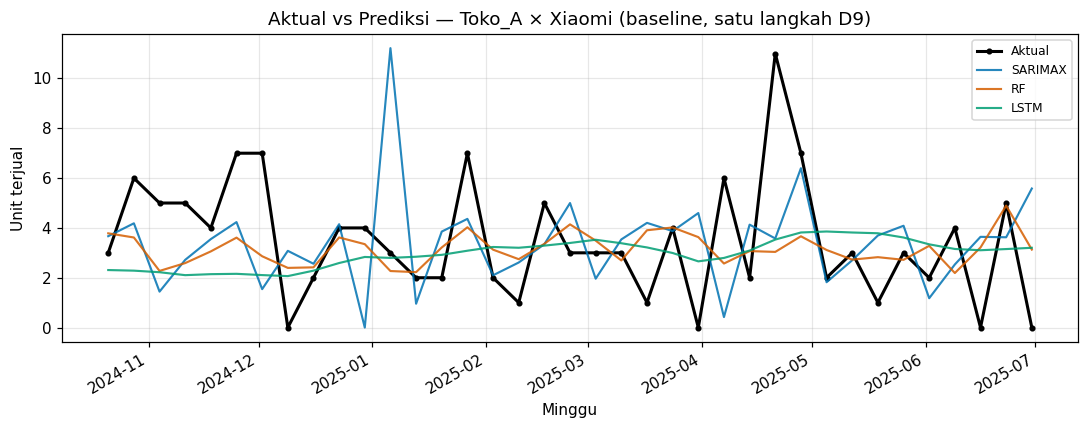

,algo,variant,n_series,MAE_mean,RMSE_mean,MAPE_mean,sMAPE_mean,MASE_mean,MAE_wmean,RMSE_wmean,MAPE_wmean,sMAPE_wmean,MASE_wmean,is_best
0,sarimax,baseline,20,1.641734,2.118356,68.066106,97.912038,0.884088,1.758556,2.296348,71.345608,93.836972,0.896523,False
1,sarimax,gt,20,1.595297,2.001764,67.145337,97.050728,0.863637,1.688314,2.125888,70.041233,93.129942,0.867742,False
2,rf,baseline,20,1.406645,1.763168,54.721488,83.881689,0.763366,1.465696,1.847125,56.459419,79.153647,0.754344,False
3,rf,gt,20,1.399524,1.746759,55.003364,83.949658,0.761813,1.455224,1.825958,56.592842,79.079001,0.750806,True
4,lstm,baseline,20,1.572478,1.896838,65.916199,85.581195,0.865263,1.620308,1.962870,67.266377,80.849512,0.843778,False
5,lstm,gt,20,1.540039,1.869890,65.716508,84.122963,0.843473,1.596184,1.943855,67.932812,79.338899,0.827993,False
6,naive,-,20,1.862162,2.406324,82.133175,101.015117,1.000000,1.961677,2.528443,82.564177,97.508360,1.000000,False
7,snaive,-,20,1.786486,2.374556,78.881622,103.483804,0.981992,1.848219,2.447073,78.810630,100.483318,0.964514,False


,group,model1,model2,dm_stat,p_value,n,significant,better
0,antar_algoritma,SARIMAX(gt),RF(gt),6.022729,2.702460e-09,740,True,RF(gt)
1,antar_algoritma,SARIMAX(gt),LSTM(gt),3.591399,3.506742e-04,740,True,LSTM(gt)
2,antar_algoritma,RF(gt),LSTM(gt),-4.482377,8.553147e-06,740,True,RF(gt)
3,ablation_gt,SARIMAX(baseline),SARIMAX(gt),1.581343,1.142276e-01,740,False,tak signifikan
4,ablation_gt,RF(baseline),RF(gt),2.485182,1.316867e-02,740,True,RF(gt)
5,ablation_gt,LSTM(baseline),LSTM(gt),1.636486,1.021638e-01,740,False,tak signifikan
6,vs_naive,SARIMAX(gt),naive,-5.088728,4.576302e-07,740,True,SARIMAX(gt)
7,vs_naive,SARIMAX(gt),snaive,-4.432096,1.074682e-05,740,True,SARIMAX(gt)
8,vs_naive,RF(gt),naive,-9.302181,1.526166e-19,740,True,RF(gt)
9,vs_naive,RF(gt),snaive,-8.344312,3.507370e-16,740,True,RF(gt)


Pemenang utama Tahap 7: ('rf', 'gt')
Kriteria D7/D10 terpenuhi: True
Jumlah kandidat D11 yang diadopsi: 0


In [7]:
evaluation_result = run_evaluation(CFG, save=True)
metrics_summary = evaluation_result["summary"]
dm_tests = evaluation_result["dm_tests"]
display(metrics_summary)
display(dm_tests)

print(f"Pemenang utama Tahap 7: {evaluation_result['best_model']}")
print(f"Kriteria D7/D10 terpenuhi: {evaluation_result['vs_naive']['meets_criteria']}")
if evaluation_result["verdict"] is not None:
    jumlah_adopsi = int(evaluation_result["verdict"]["signif_better_than_old"].astype(bool).sum())
    print(f"Jumlah kandidat D11 yang diadopsi: {jumlah_adopsi}")

In [8]:
EXPECTED_RESULT_KEYS = {
    "per_series", "summary", "dm_tests", "ablation", "best_model",
    "best_variant", "runner_up", "smape_floor", "verdict",
    "final_winner", "vs_naive",
}
assert set(evaluation_result.keys()) == EXPECTED_RESULT_KEYS

EXPECTED_FILES = {
    "metrics_per_series.csv": (
        (120, 12),
        {"algo", "variant", "store", "brand", "MAE", "RMSE", "MAPE", "sMAPE", "MASE", "n", "n_nonzero", "volume"},
        "per_series",
    ),
    "metrics_summary.csv": (
        (8, 14),
        {"algo", "variant", "n_series", "MAE_mean", "RMSE_mean", "MAPE_mean", "sMAPE_mean", "MASE_mean", "MAE_wmean", "RMSE_wmean", "MAPE_wmean", "sMAPE_wmean", "MASE_wmean", "is_best"},
        "summary",
    ),
    "dm_tests.csv": (
        (22, 8),
        {"group", "model1", "model2", "dm_stat", "p_value", "n", "significant", "better"},
        "dm_tests",
    ),
    "gt_ablation_comparison.csv": (
        (63, 16),
        {"row_type", "algo", "store", "brand", "MAPE_baseline", "MAPE_gt", "delta_MAPE_pct", "MAE_baseline", "MAE_gt", "delta_MAE", "dm_stat", "dm_p", "verdict", "n_membaik", "n_memburuk", "n_tak_signifikan"},
        "ablation",
    ),
    "smape_theoretical_floor.csv": (
        (20, 6),
        {"store", "brand", "lambda_test", "smape_floor_oracle", "smape_actual_best", "gap_vs_floor"},
        "smape_floor",
    ),
    "accuracy_improvement_verdict.csv": (
        (11, 7),
        {"candidate", "MAE_mean", "MASE_mean", "dm_stat", "p_value_vs_old_winner", "signif_better_than_old", "decision"},
        "verdict",
    ),
}

reloaded_outputs = {}
for filename, (expected_shape, expected_columns, result_key) in EXPECTED_FILES.items():
    reloaded = pd.read_csv(rp("reports", "results", filename))
    reloaded_outputs[result_key] = reloaded
    assert reloaded.shape == expected_shape, (filename, reloaded.shape)
    assert set(reloaded.columns) == expected_columns, (filename, list(reloaded.columns))
    produced = evaluation_result[result_key]
    assert isinstance(produced, pd.DataFrame), (result_key, type(produced))
    assert produced.equals(reloaded), filename

assert evaluation_result["best_model"] == ("rf", "gt")
assert evaluation_result["final_winner"] == ("rf", "gt")
assert evaluation_result["summary"].loc[
    (evaluation_result["summary"]["algo"] == "rf") & (evaluation_result["summary"]["variant"] == "gt"),
    "MASE_mean"
].iloc[0] < 1
assert bool(evaluation_result["vs_naive"]["naive"]["sig_better"])
assert bool(evaluation_result["vs_naive"]["snaive"]["sig_better"])

all_groups = set(reloaded_outputs["dm_tests"]["group"])
assert all_groups == {"antar_algoritma", "ablation_gt", "vs_naive", "kandidat_akurasi"}
assert reloaded_outputs["dm_tests"].groupby("group").size().to_dict() == {
    "ablation_gt": 3, "antar_algoritma": 3, "kandidat_akurasi": 10, "vs_naive": 6,
}

candidate_table = reloaded_outputs["verdict"]
assert len(candidate_table) == 11
assert candidate_table["candidate"].str.contains("pemenang lama", regex=False).sum() == 1
assert (~candidate_table.loc[~candidate_table["candidate"].str.contains("pemenang lama", regex=False), "signif_better_than_old"].astype(bool)).all()

assert FIGURE_AUDIT, "Tidak ada figur aktual-vs-prediksi yang diaudit."
assert any(item["path"].exists() and item["path"].stat().st_size > 0 for item in FIGURE_AUDIT)
inline_figures = [item for item in FIGURE_AUDIT if item["displayed_inline"]]
assert inline_figures, "Tidak ada figur aktual-vs-prediksi yang ditampilkan inline."
assert any(
    item["line_count"] > 0
    and item["legend_visible"]
    and item["title"].startswith("Aktual vs Prediksi")
    and item["xlabel"] == "Minggu"
    and item["ylabel"] == "Unit terjual"
    for item in inline_figures
), inline_figures

def R(*x): return pd.read_csv(rp("reports", "results", *x))


def select_dm_row(dm_table: pd.DataFrame, group: str, model1_sub: str, model2_sub: str, model2_exact: bool = False) -> pd.DataFrame:
    model2_mask = (
        dm_table["model2"].eq(model2_sub)
        if model2_exact
        else dm_table["model2"].str.contains(model2_sub, regex=False)
    )
    return dm_table[
        (dm_table["group"] == group)
        & dm_table["model1"].str.contains(model1_sub, regex=False)
        & model2_mask
    ]


summary = R("metrics_summary.csv")
best = summary[(summary["algo"] == "rf") & (summary["variant"] == "gt")].iloc[0]
assert bool(best["is_best"]), "RF·gt bukan is_best"
assert abs(best["MAE_mean"] - 1.3995) < 0.02, best["MAE_mean"]
assert abs(best["MASE_mean"] - 0.7618) < 0.01, best["MASE_mean"]

dm = R("dm_tests.csv")
def dmp(group, m1_sub, m2_sub, model2_exact=False):
    r = select_dm_row(dm, group, m1_sub, m2_sub, model2_exact=model2_exact)
    assert len(r) == 1, (group, m1_sub, m2_sub, len(r))
    return float(r["p_value"].iloc[0])

assert dmp("antar_algoritma", "SARIMAX", "RF(gt)") < 1e-3
assert dmp("antar_algoritma", "RF(gt)", "LSTM") < 1e-3
assert dmp("vs_naive", "RF(gt)", "naive", model2_exact=True) < 1e-3
assert dmp("vs_naive", "RF(gt)", "snaive", model2_exact=True) < 1e-3
assert dmp("ablation_gt", "RF(baseline)", "RF(gt)") < 0.05
assert dmp("ablation_gt", "SARIMAX", "SARIMAX(gt)") > 0.05
assert dmp("ablation_gt", "LSTM(baseline)", "LSTM(gt)") > 0.05
rf_abl = dm[(dm["group"] == "ablation_gt")
            & dm["model2"].str.contains("RF(gt)", regex=False)].iloc[0]
assert abs(abs(rf_abl["dm_stat"]) - 2.4852) < 0.05 and abs(rf_abl["p_value"] - 0.0132) < 0.005

floor = R("smape_theoretical_floor.csv")
assert abs(floor["smape_actual_best"].mean() - 83.95) < 1.5
assert abs(floor["smape_floor_oracle"].mean() - 67.42) < 1.5

verdict = R("accuracy_improvement_verdict.csv")
cand = verdict[~verdict["candidate"].str.contains("pemenang lama", regex=False)]
assert len(cand) == 10 and (~cand["signif_better_than_old"].astype(bool)).all()
print("✅ Tahap 7: RF·gt terbaik & lulus semua kriteria D5/D7/D9/D10/D11")

✅ Tahap 7: RF·gt terbaik & lulus semua kriteria D5/D7/D9/D10/D11
